# ĐỒ ÁN 1: DỰ ĐOÁN THU NHẬP CÁ NHÂN (US ADULT CENSUS)
## Phần 2: Xây dựng và Đánh giá Mô hình Machine Learning (Task 8)
**Người thực hiện: Đào Đoàn Huy Phúc & Cao Nguyên Ngọc**
- Mô hình 1: Logistic Regression
- Mô hình 2: Decision Tree Classifier

### 1. Import thư viện và tải dữ liệu đã làm sạch

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

%matplotlib inline
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

df = pd.read_csv('../data/adult_cleaned.csv')
print('Kích thước tập dữ liệu sạch:', df.shape)
df.head(3)

Kích thước tập dữ liệu sạch: (32537, 16)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,income_num
0,90,Private,77053,HS-grad,9,Widowed,Prof-specialty,Not-in-family,White,Female,0,4356,40,United-States,<=50K,0
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K,0
2,66,Private,186061,Some-college,10,Widowed,Prof-specialty,Unmarried,Black,Female,0,4356,40,United-States,<=50K,0


### 2. Tiền xử lý dữ liệu cho Machine Learning
- Chọn lọc đặc trưng đầu vào.
- Mã hóa One-Hot Encoding cho các biến phân loại.
- Chia tập Train/Test theo tỷ lệ 80/20 có Stratified Split.
- Chuẩn hóa StandardScaler cho các biến định lượng.

In [2]:
feature_cols = [
    'age', 'workclass', 'education_num', 'marital_status',
    'occupation', 'relationship', 'race', 'sex',
    'capital_gain', 'capital_loss', 'hours_per_week'
]
X = df[feature_cols].copy()
y = df['income_num'].copy()

cat_cols = ['workclass', 'marital_status', 'occupation', 'relationship', 'race', 'sex']
num_cols = ['age', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

# One-Hot Encoding
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)
feature_names = X_encoded.columns.tolist()

# Phân chia Train/Test 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# Chuẩn hóa biến số
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print(f'Tập Train: {X_train.shape[0]} mẫu, {X_train.shape[1]} đặc trưng')
print(f'Tập Test:  {X_test.shape[0]} mẫu, {X_test.shape[1]} đặc trưng')

Tập Train: 26029 mẫu, 41 đặc trưng
Tập Test:  6508 mẫu, 41 đặc trưng


### 3. Huấn luyện các mô hình Machine Learning

In [3]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=7, min_samples_split=20, random_state=42)
}

y_preds = {}
y_probas = {}
results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    
    y_preds[name] = y_pred
    y_probas[name] = y_proba
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    
    results.append({
        'Mô hình': name,
        'Accuracy': round(acc, 4),
        'Precision (>50K)': round(prec, 4),
        'Recall (>50K)': round(rec, 4),
        'F1-Score (>50K)': round(f1, 4),
        'ROC-AUC': round(auc, 4)
    })

res_df = pd.DataFrame(results)
res_df

,Mô hình,Accuracy,Precision (>50K),Recall (>50K),F1-Score (>50K),ROC-AUC
0,Logistic Regression,0.8522,0.7367,0.6014,0.6622,0.8996
1,Decision Tree,0.8548,0.7930,0.5376,0.6408,0.8950


### 4. Báo cáo phân loại chi tiết (Classification Reports)

In [4]:
for name, y_pred in y_preds.items():
    print(f'=== BÁO CÁO PHÂN LOẠI: {name} ===')
    print(classification_report(y_test, y_pred, target_names=['<=50K', '>50K']))

=== BÁO CÁO PHÂN LOẠI: Logistic Regression ===
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      4940
        >50K       0.74      0.60      0.66      1568

    accuracy                           0.85      6508
   macro avg       0.81      0.77      0.78      6508
weighted avg       0.85      0.85      0.85      6508

=== BÁO CÁO PHÂN LOẠI: Decision Tree ===
              precision    recall  f1-score   support

       <=50K       0.87      0.96      0.91      4940
        >50K       0.79      0.54      0.64      1568

    accuracy                           0.85      6508
   macro avg       0.83      0.75      0.77      6508
weighted avg       0.85      0.85      0.84      6508



### 5. Ma trận nhầm lẫn (Confusion Matrix)

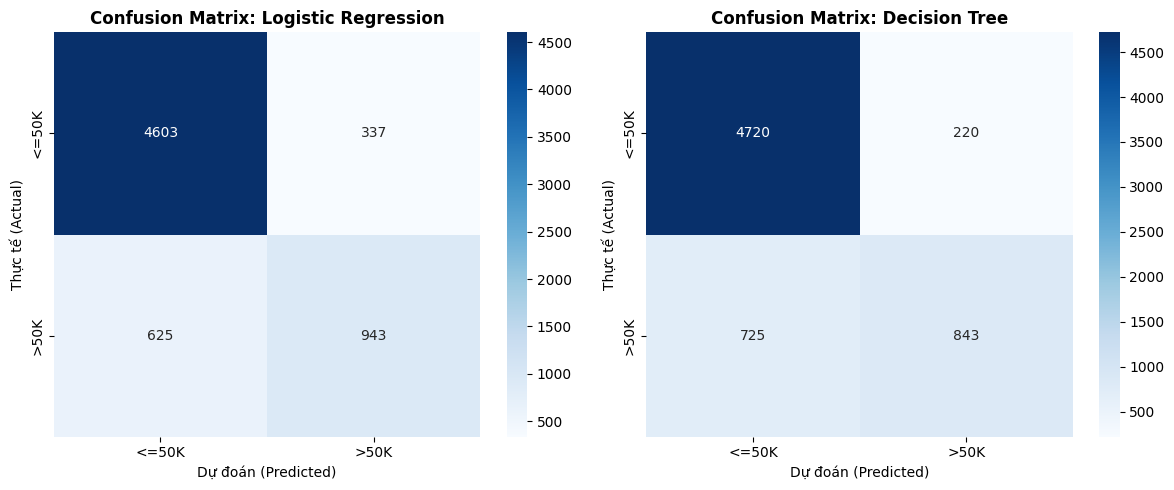

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for idx, (name, y_pred) in enumerate(y_preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['<=50K', '>50K'], yticklabels=['<=50K', '>50K'])
    axes[idx].set_title(f'Confusion Matrix: {name}', fontweight='bold')
    axes[idx].set_xlabel('Dự đoán (Predicted)')
    axes[idx].set_ylabel('Thực tế (Actual)')
plt.tight_layout()
plt.show()

### 6. Đường cong ROC Curves & AUC

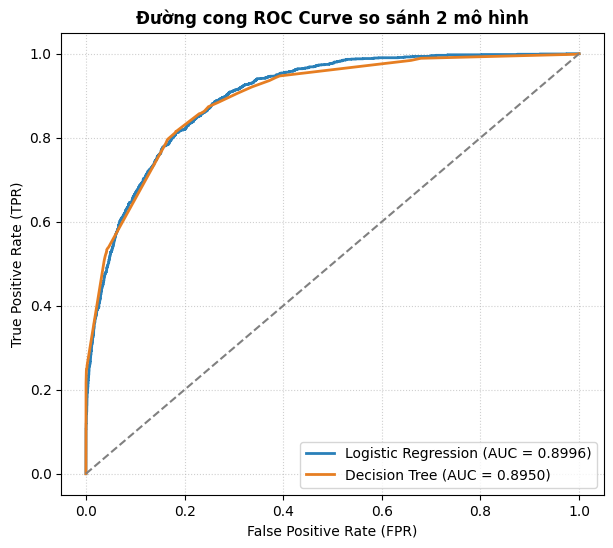

In [6]:
plt.figure(figsize=(7, 6))
colors = ['#2980b9', '#e67e22']
for idx, (name, y_proba) in enumerate(y_probas.items()):
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, color=colors[idx], lw=2, label=f'{name} (AUC = {auc:.4f})')

plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.title('Đường cong ROC Curve so sánh 2 mô hình', fontsize=12, fontweight='bold')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### 7. Đặc trưng quan trọng nhất (Feature Importance - Decision Tree)

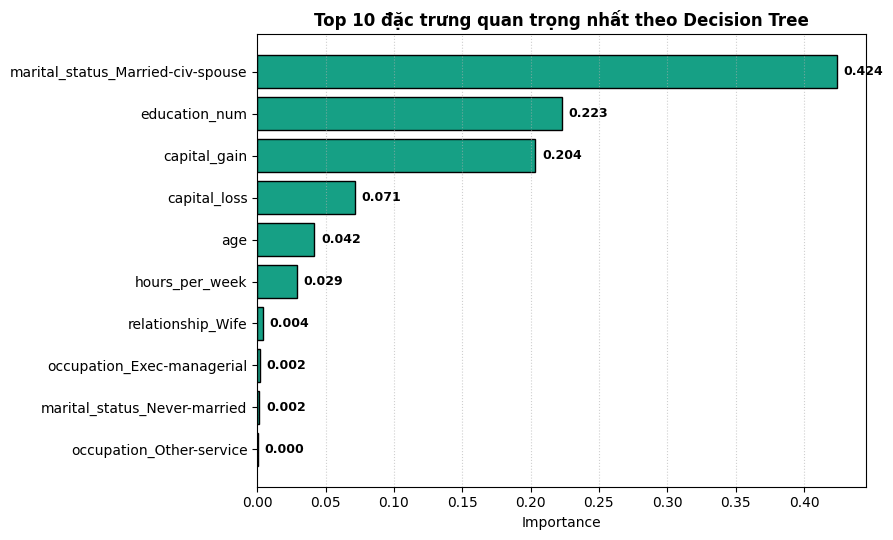

In [7]:
dt = models['Decision Tree']
feat_df = pd.DataFrame({'Feature': feature_names, 'Importance': dt.feature_importances_})
feat_df = feat_df.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(9, 5.5))
bars = plt.barh(feat_df['Feature'][::-1], feat_df['Importance'][::-1], color='#16a085', edgecolor='black')
plt.title('Top 10 đặc trưng quan trọng nhất theo Decision Tree', fontsize=12, fontweight='bold')
plt.xlabel('Importance')
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.005, bar.get_y() + bar.get_height()/2., f'{w:.3f}', va='center', fontweight='bold', fontsize=9)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()